<a href="https://colab.research.google.com/github/Rupesh756/Brain-tumor-Detection-using-deep-learning/blob/main/3D_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumorProject"

folders = [
    BASE_DIR,
    f"{BASE_DIR}/dataset",
    f"{BASE_DIR}/checkpoints",
    f"{BASE_DIR}/results",
    f"{BASE_DIR}/logs",
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

print("Project folders created successfully!")
print(BASE_DIR)

Project folders created successfully!
/content/drive/MyDrive/BrainTumorProject


In [6]:
!pip install -q monai nibabel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 13.9 MB/s eta 0:00:00


In [7]:
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumorProject"

DATASET_DIR = f"{BASE_DIR}/dataset/Task01_BrainTumour"

CHECKPOINT_DIR = f"{BASE_DIR}/checkpoints"

RESULTS_DIR = f"{BASE_DIR}/results"

LOGS_DIR = f"{BASE_DIR}/logs"

print("BASE_DIR:", BASE_DIR)
print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Checkpoint folder exists:", os.path.exists(CHECKPOINT_DIR))

BASE_DIR: /content/drive/MyDrive/BrainTumorProject
Dataset exists: True
Checkpoint folder exists: True


In [8]:
import os

print("Checkpoint files:\n")

for root, dirs, files in os.walk(CHECKPOINT_DIR):
    for file in files:
        print(os.path.join(root, file))

Checkpoint files:

/content/drive/MyDrive/BrainTumorProject/checkpoints/best_model.pth
/content/drive/MyDrive/BrainTumorProject/checkpoints/latest_model.pth
/content/drive/MyDrive/BrainTumorProject/checkpoints/version1/best_model_v1.pth
/content/drive/MyDrive/BrainTumorProject/checkpoints/version1/latest_model_v1.pth


In [6]:
import os

ARCHIVE_PATH = f"{BASE_DIR}/dataset/Task01_BrainTumour.tar"

if os.path.exists(ARCHIVE_PATH):
    print("Dataset archive already downloaded!")
else:
    print("Downloading dataset...")
    !wget -c -O "$ARCHIVE_PATH" \
    https://msd-for-monai.s3-us-west-2.amazonaws.com/Task01_BrainTumour.tar

--2026-09-07 13:35:02--  https://msd-for-monai.s3-us-west-2.amazonaws.com/Task01_BrainTumour.tar
Resolving msd-for-monai.s3-us-west-2.amazonaws.com (msd-for-monai.s3-us-west-2.amazonaws.com)... 52.218.183.130, 52.92.248.26, 16.12.97.130, ...
Connecting to msd-for-monai.s3-us-west-2.amazonaws.com (msd-for-monai.s3-us-west-2.amazonaws.com)|52.218.183.130|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 7608266240 (7.1G) [application/x-tar]
Saving to: ‘/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour.tar’

/content/drive/MyDr 100%[===================>]   7.08G  44.7MB/s    in 4m 17s  

2026-09-07 13:39:19 (28.3 MB/s) - ‘/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour.tar’ saved [7608266240/7608266240]



In [7]:
import os
import tarfile

DATASET_DIR = f"{BASE_DIR}/dataset/Task01_BrainTumour"

if os.path.exists(DATASET_DIR):
    print("Dataset already extracted!")
else:
    print("Extracting dataset...")

    with tarfile.open(ARCHIVE_PATH, "r") as tar:
        tar.extractall(f"{BASE_DIR}/dataset")

    print("Extraction completed!")

Extracting dataset...


/tmp/ipykernel_280/3309779076.py:12: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall(f"{BASE_DIR}/dataset")


Extraction completed!


In [8]:
import glob
import os

images_path = f"{DATASET_DIR}/imagesTr"
labels_path = f"{DATASET_DIR}/labelsTr"

images = sorted(glob.glob(f"{images_path}/*.nii.gz"))
labels = sorted(glob.glob(f"{labels_path}/*.nii.gz"))

print("Dataset location:", DATASET_DIR)
print("Training MRI files:", len(images))
print("Training masks:", len(labels))

print("\nFirst image:")
print(os.path.basename(images[0]) if images else "No files found")

Dataset location: /content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour
Training MRI files: 484
Training masks: 484

First image:
BRATS_001.nii.gz


In [9]:
import os
import glob
import json
from sklearn.model_selection import train_test_split

# Dataset paths
images_path = f"{DATASET_DIR}/imagesTr"
labels_path = f"{DATASET_DIR}/labelsTr"

# Get all MRI files
images = sorted(glob.glob(f"{images_path}/*.nii.gz"))

# Use first 30 patients initially
selected_images = images[:30]

# Create image-label pairs
data = []

for img_path in selected_images:

    filename = os.path.basename(img_path)
    label_path = f"{labels_path}/{filename}"

    data.append({
        "image": img_path,
        "label": label_path
    })

# Split dataset
train_files, val_files = train_test_split(
    data,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

# Save split permanently
split_path = f"{BASE_DIR}/dataset/data_split.json"

split_data = {
    "train": train_files,
    "validation": val_files
}

with open(split_path, "w") as f:
    json.dump(split_data, f, indent=4)

print("Dataset split created and saved!")

print("\nTraining patients:", len(train_files))
print("Validation patients:", len(val_files))

print("\nSplit saved at:")
print(split_path)

Dataset split created and saved!

Training patients: 24
Validation patients: 6

Split saved at:
/content/drive/MyDrive/BrainTumorProject/dataset/data_split.json


In [10]:
import json

split_path = f"{BASE_DIR}/dataset/data_split.json"

with open(split_path, "r") as f:
    saved_split = json.load(f)

print("Training patients:", len(saved_split["train"]))
print("Validation patients:", len(saved_split["validation"]))

print("\nExample training patient:")
print(saved_split["train"][0])

Training patients: 24
Validation patients: 6

Example training patient:
{'image': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/imagesTr/BRATS_029.nii.gz', 'label': '/content/drive/MyDrive/BrainTumorProject/dataset/Task01_BrainTumour/labelsTr/BRATS_029.nii.gz'}


In [11]:
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    NormalizeIntensityd,
    Resized,
    RandFlipd,
    RandRotate90d,
    EnsureTyped
)

train_transforms = Compose([

    # Load MRI and segmentation mask
    LoadImaged(keys=["image", "label"]),

    # Move MRI modality axis to channel dimension
    EnsureChannelFirstd(
        keys="image",
        channel_dim=-1
    ),

    # Add channel dimension to label
    EnsureChannelFirstd(
        keys="label",
        channel_dim="no_channel"
    ),

    # Normalize MRI intensities
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    # Resize image and label
    Resized(
        keys=["image", "label"],
        spatial_size=(128, 128, 96),
        mode=("trilinear", "nearest")
    ),

    # Data augmentation
    RandFlipd(
        keys=["image", "label"],
        prob=0.5,
        spatial_axis=0
    ),

    RandRotate90d(
        keys=["image", "label"],
        prob=0.3,
        max_k=3
    ),

    EnsureTyped(keys=["image", "label"])
])


# Validation transforms (no augmentation)
val_transforms = Compose([

    LoadImaged(keys=["image", "label"]),

    EnsureChannelFirstd(
        keys="image",
        channel_dim=-1
    ),

    EnsureChannelFirstd(
        keys="label",
        channel_dim="no_channel"
    ),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True
    ),

    Resized(
        keys=["image", "label"],
        spatial_size=(128, 128, 96),
        mode=("trilinear", "nearest")
    ),

    EnsureTyped(keys=["image", "label"])
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [12]:
test_data = train_transforms(train_files[0])

print("Image Shape:", test_data["image"].shape)
print("Label Shape:", test_data["label"].shape)

print("\nImage Type:", test_data["image"].dtype)
print("Label Type:", test_data["label"].dtype)

print("\nUnique Label Values:")
print(test_data["label"].unique())

Image Shape: torch.Size([4, 128, 128, 96])
Label Shape: torch.Size([1, 128, 128, 96])

Image Type: torch.float32
Label Type: torch.float32

Unique Label Values:
metatensor([0., 1., 2.])


In [13]:
from monai.data import Dataset, DataLoader

# Create datasets
train_dataset = Dataset(
    data=train_files,
    transform=train_transforms
)

val_dataset = Dataset(
    data=val_files,
    transform=val_transforms
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train dataset size:", len(train_dataset))
print("Validation dataset size:", len(val_dataset))

Train dataset size: 24
Validation dataset size: 6


In [14]:
batch = next(iter(train_loader))

images_batch = batch["image"]
labels_batch = batch["label"]

print("Batch Image Shape:", images_batch.shape)
print("Batch Label Shape:", labels_batch.shape)

print("\nImage Device:", images_batch.device)
print("Image Type:", images_batch.dtype)

print("\nLabel Values:")
print(torch.unique(labels_batch))

Batch Image Shape: torch.Size([1, 4, 128, 128, 96])
Batch Label Shape: torch.Size([1, 1, 128, 128, 96])

Image Device: cpu
Image Type: torch.float32

Label Values:
metatensor([0., 1., 2., 3.])


In [15]:
# Building Lightweight 3D U-Net
import torch
import torch.nn as nn


class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        self.block = nn.Sequential(

            nn.Conv3d(
                in_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True),

            nn.Conv3d(
                out_channels,
                out_channels,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm3d(out_channels),

            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class Lightweight3DUNet(nn.Module):

    def __init__(
        self,
        in_channels=4,
        num_classes=4
    ):

        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(in_channels, 16)

        self.pool1 = nn.MaxPool3d(2)


        self.enc2 = ConvBlock(16, 32)

        self.pool2 = nn.MaxPool3d(2)


        self.enc3 = ConvBlock(32, 64)

        self.pool3 = nn.MaxPool3d(2)


        # Bottleneck
        self.bottleneck = ConvBlock(64, 128)


        # Decoder

        self.up3 = nn.ConvTranspose3d(
            128,
            64,
            kernel_size=2,
            stride=2
        )

        self.dec3 = ConvBlock(
            128,
            64
        )


        self.up2 = nn.ConvTranspose3d(
            64,
            32,
            kernel_size=2,
            stride=2
        )

        self.dec2 = ConvBlock(
            64,
            32
        )


        self.up1 = nn.ConvTranspose3d(
            32,
            16,
            kernel_size=2,
            stride=2
        )

        self.dec1 = ConvBlock(
            32,
            16
        )


        # Output layer

        self.output = nn.Conv3d(
            16,
            num_classes,
            kernel_size=1
        )


    def forward(self, x):

        # Encoder

        e1 = self.enc1(x)

        p1 = self.pool1(e1)


        e2 = self.enc2(p1)

        p2 = self.pool2(e2)


        e3 = self.enc3(p2)

        p3 = self.pool3(e3)


        # Bottleneck

        b = self.bottleneck(p3)


        # Decoder

        d3 = self.up3(b)

        d3 = torch.cat(
            [d3, e3],
            dim=1
        )

        d3 = self.dec3(d3)


        d2 = self.up2(d3)

        d2 = torch.cat(
            [d2, e2],
            dim=1
        )

        d2 = self.dec2(d2)


        d1 = self.up1(d2)

        d1 = torch.cat(
            [d1, e1],
            dim=1
        )

        d1 = self.dec1(d1)


        return self.output(d1)

In [16]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = Lightweight3DUNet(
    in_channels=4,
    num_classes=4
).to(device)

print("Device:", device)

print("\nModel created successfully!")

# Count parameters
total_params = sum(
    p.numel()
    for p in model.parameters()
)

print(
    f"Total Parameters: "
    f"{total_params:,}"
)

Device: cuda

Model created successfully!
Total Parameters: 1,403,316


In [17]:
# Get one batch
batch = next(iter(train_loader))

x = batch["image"].float().to(device)

print("Input Shape:", x.shape)

# Test model
with torch.no_grad():

    output = model(x)

print("Output Shape:", output.shape)

Input Shape: torch.Size([1, 4, 128, 128, 96])
Output Shape: torch.Size([1, 4, 128, 128, 96])


In [18]:
import torch
import torch.nn as nn
from torch.optim import AdamW

# Loss function
criterion = nn.CrossEntropyLoss()

# Optimizer
optimizer = AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5
)

# Training configuration
NUM_EPOCHS = 20

# Mixed precision
scaler = torch.cuda.amp.GradScaler()

# Permanent checkpoint paths
CHECKPOINT_DIR = f"{BASE_DIR}/checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

LATEST_CHECKPOINT = f"{CHECKPOINT_DIR}/latest_model.pth"
BEST_CHECKPOINT = f"{CHECKPOINT_DIR}/best_model.pth"

print("Training configuration ready!")
print("Epochs:", NUM_EPOCHS)
print("Checkpoint folder:", CHECKPOINT_DIR)

Training configuration ready!
Epochs: 20
Checkpoint folder: /content/drive/MyDrive/BrainTumorProject/checkpoints


/tmp/ipykernel_280/1225263051.py:19: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


In [19]:
def dice_score(pred, target, num_classes=4):
    """
    Calculate mean Dice score for tumor classes.
    Background (class 0) is excluded.
    """

    dice_scores = []

    for class_id in range(1, num_classes):

        pred_class = (pred == class_id).float()
        target_class = (target == class_id).float()

        intersection = (pred_class * target_class).sum()

        denominator = (
            pred_class.sum() +
            target_class.sum()
        )

        if denominator == 0:
            continue

        dice = (
            2.0 * intersection + 1e-6
        ) / (
            denominator + 1e-6
        )

        dice_scores.append(dice.item())

    if len(dice_scores) == 0:
        return 0.0

    return sum(dice_scores) / len(dice_scores)


print("Dice Score function ready!")

Dice Score function ready!


In [20]:
batch = next(iter(train_loader))

images_test = batch["image"].float().to(device)

labels_test = batch["label"].long().to(device)

# Remove channel dimension
labels_test = labels_test.squeeze(1)

print("Images:", images_test.shape)
print("Labels:", labels_test.shape)

# Test loss
with torch.no_grad():
    outputs_test = model(images_test)
    loss_test = criterion(outputs_test, labels_test)

print("Test Loss:", loss_test.item())

Images: torch.Size([1, 4, 128, 128, 96])
Labels: torch.Size([1, 128, 128, 96])
Test Loss: 1.377953052520752


In [21]:
import json

HISTORY_PATH = f"{BASE_DIR}/logs/training_history.json"

if not os.path.exists(HISTORY_PATH):

    history = {
        "train_loss": [],
        "val_loss": [],
        "val_dice": []
    }

    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f)

    print("New training history created!")

else:
    print("Training history already exists!")

New training history created!


In [22]:
import os
import json
import torch
from tqdm import tqdm

# -----------------------------------
# Resume from checkpoint if available
# -----------------------------------

start_epoch = 0
best_dice = 0.0

if os.path.exists(LATEST_CHECKPOINT):

    print("Loading previous checkpoint...")

    checkpoint = torch.load(
        LATEST_CHECKPOINT,
        map_location=device
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    start_epoch = checkpoint["epoch"] + 1
    best_dice = checkpoint["best_dice"]

    print(f"Resuming from epoch {start_epoch}")

else:
    print("Starting training from scratch!")


# -----------------------------------
# Load training history
# -----------------------------------

with open(HISTORY_PATH, "r") as f:
    history = json.load(f)


# -----------------------------------
# Training loop
# -----------------------------------

for epoch in range(start_epoch, NUM_EPOCHS):

    print("\n" + "=" * 60)
    print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")
    print("=" * 60)


    # ===============================
    # TRAINING
    # ===============================

    model.train()

    running_loss = 0.0

    train_bar = tqdm(
        train_loader,
        desc="Training"
    )


    for batch in train_bar:

        images_batch = (
            batch["image"]
            .float()
            .to(device)
        )

        labels_batch = (
            batch["label"]
            .long()
            .squeeze(1)
            .to(device)
        )


        optimizer.zero_grad()


        # Mixed precision training
        with torch.cuda.amp.autocast():

            outputs = model(images_batch)

            loss = criterion(
                outputs,
                labels_batch
            )


        # Backpropagation

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()


        running_loss += loss.item()


        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )


    avg_train_loss = (
        running_loss /
        len(train_loader)
    )


    # ===============================
    # VALIDATION
    # ===============================

    model.eval()

    val_loss = 0.0

    val_dice_scores = []


    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc="Validation"
        )


        for batch in val_bar:

            images_batch = (
                batch["image"]
                .float()
                .to(device)
            )

            labels_batch = (
                batch["label"]
                .long()
                .squeeze(1)
                .to(device)
            )


            with torch.cuda.amp.autocast():

                outputs = model(images_batch)

                loss = criterion(
                    outputs,
                    labels_batch
                )


            val_loss += loss.item()


            # Convert predictions

            predictions = torch.argmax(
                outputs,
                dim=1
            )


            # Dice Score

            dice = dice_score(
                predictions,
                labels_batch
            )

            val_dice_scores.append(dice)


    avg_val_loss = (
        val_loss /
        len(val_loader)
    )

    avg_val_dice = (
        sum(val_dice_scores) /
        len(val_dice_scores)
    )


    # ===============================
    # SAVE HISTORY
    # ===============================

    history["train_loss"].append(
        avg_train_loss
    )

    history["val_loss"].append(
        avg_val_loss
    )

    history["val_dice"].append(
        avg_val_dice
    )


    with open(HISTORY_PATH, "w") as f:

        json.dump(
            history,
            f,
            indent=4
        )


    # ===============================
    # SAVE LATEST CHECKPOINT
    # ===============================

    checkpoint = {

        "epoch": epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "best_dice":
            best_dice

    }


    torch.save(
        checkpoint,
        LATEST_CHECKPOINT
    )


    # ===============================
    # SAVE BEST MODEL
    # ===============================

    if avg_val_dice > best_dice:

        best_dice = avg_val_dice

        torch.save(
            checkpoint,
            BEST_CHECKPOINT
        )

        print(
            "\n🔥 New Best Model Saved!"
        )


    # ===============================
    # PRINT RESULTS
    # ===============================

    print("\nResults:")

    print(
        f"Train Loss: {avg_train_loss:.4f}"
    )

    print(
        f"Validation Loss: {avg_val_loss:.4f}"
    )

    print(
        f"Validation Dice: {avg_val_dice:.4f}"
    )


    # Free GPU memory

    torch.cuda.empty_cache()


print("\n🎉 TRAINING COMPLETED!")

Starting training from scratch!

Epoch 1/20


Training:   0%|          | 0/24 [00:00<?, ?it/s]/tmp/ipykernel_280/1572672010.py:92: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Validation:   0%|          | 0/6 [00:00<?, ?it/s]/tmp/ipykernel_280/1572672010.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Validation: 100%|██████████| 6/6 [00:09<00:00,  1.54s/it]



🔥 New Best Model Saved!

Results:
Train Loss: 1.2864
Validation Loss: 1.2837
Validation Dice: 0.1042

Epoch 2/20


Validation: 100%|██████████| 6/6 [00:10<00:00,  1.75s/it]



🔥 New Best Model Saved!

Results:
Train Loss: 1.1962
Validation Loss: 1.1713
Validation Dice: 0.1141

Epoch 3/20


Validation: 100%|██████████| 6/6 [00:10<00:00,  1.75s/it]


... (31 outputs left out)

Validation: 100%|██████████| 6/6 [00:09<00:00,  1.63s/it]



Results:
Train Loss: 0.6669
Validation Loss: 0.6508
Validation Dice: 0.1691

Epoch 20/20


Validation: 100%|██████████| 6/6 [00:08<00:00,  1.43s/it]



Results:
Train Loss: 0.6456
Validation Loss: 0.6278
Validation Dice: 0.1721

🎉 TRAINING COMPLETED!


In [23]:
import json
import os

with open(HISTORY_PATH, "r") as f:
    history = json.load(f)

print("Total completed epochs:", len(history["train_loss"]))

print("\nTrain Loss History:")
print(history["train_loss"])

print("\nValidation Dice History:")
print(history["val_dice"])

print("\nLatest checkpoint exists:", os.path.exists(LATEST_CHECKPOINT))
print("Best model exists:", os.path.exists(BEST_CHECKPOINT))

Total completed epochs: 20

Train Loss History:
[1.286446988582611, 1.196163351337115, 1.145266905426979, 1.0879235217968624, 1.0398892064889271, 1.0033156424760818, 0.970867765446504, 0.9407959307233492, 0.9121557076772054, 0.8841067999601364, 0.8570242548982302, 0.8310395429531733, 0.805739680926005, 0.7810401320457458, 0.7568221067388853, 0.7335705682635307, 0.7108853707710902, 0.6887971609830856, 0.6669354339440664, 0.6455819681286812]

Validation Dice History:
[0.1041543963883322, 0.11407173067026478, 0.09734609284668322, 0.1833843010906749, 0.18596535196183753, 0.19165539616892224, 0.1913645090698284, 0.18380236163918554, 0.17870082361781228, 0.17506119231264564, 0.171537966120462, 0.17099142361337114, 0.17027012930040852, 0.17046806427128589, 0.1703783613698363, 0.170487267011307, 0.16620496525579356, 0.17196687738076424, 0.16913218549640685, 0.17213156854679987]

Latest checkpoint exists: True
Best model exists: True


In [24]:
checkpoint = torch.load(
    LATEST_CHECKPOINT,
    map_location=device
)

print("Last completed epoch:", checkpoint["epoch"] + 1)
print("Best Dice:", checkpoint["best_dice"])
print("NUM_EPOCHS setting:", NUM_EPOCHS)

Last completed epoch: 20
Best Dice: 0.19165539616892224
NUM_EPOCHS setting: 20


In [25]:
# Load best model
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Best model loaded!")
print("Best Dice:", checkpoint["best_dice"])

Best model loaded!
Best Dice: 0.18596535196183753


Selected slice: 36


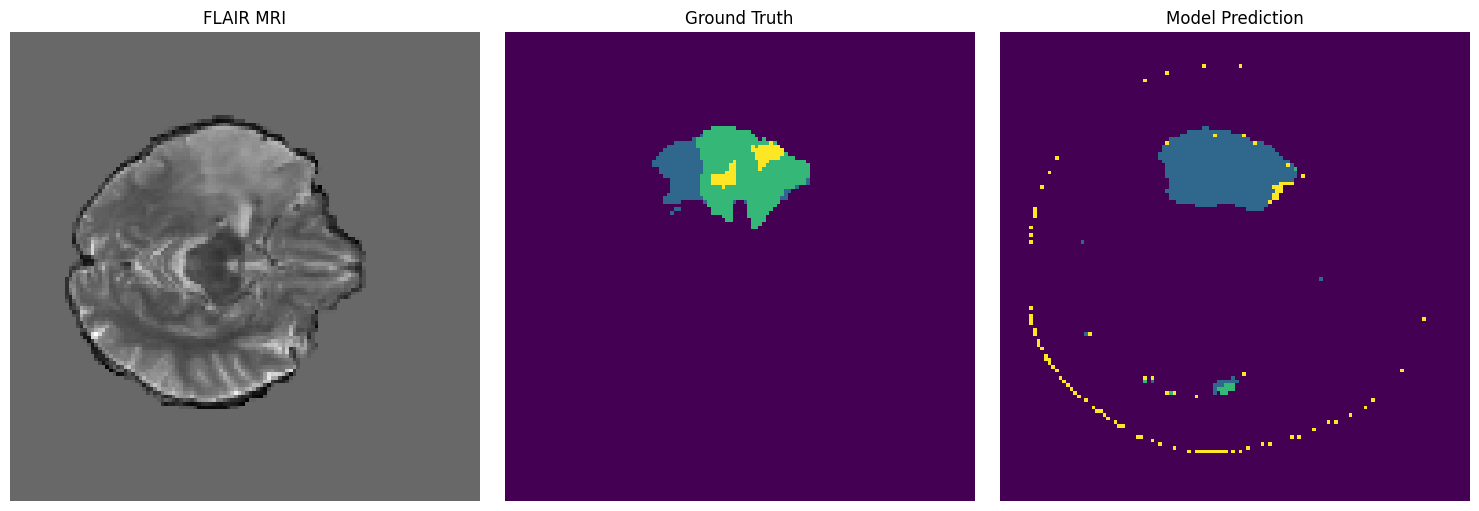

In [26]:
import matplotlib.pyplot as plt
import numpy as np

# Get validation sample
sample = next(iter(val_loader))

image_sample = sample["image"].float().to(device)
label_sample = sample["label"].squeeze(1).cpu().numpy()[0]

# Prediction
with torch.no_grad():
    output = model(image_sample)
    prediction = torch.argmax(output, dim=1).cpu().numpy()[0]

# Find a slice containing tumor
tumor_slices = np.where(
    np.sum(label_sample > 0, axis=(0, 1)) > 0
)[0]

slice_idx = tumor_slices[len(tumor_slices) // 2]

print("Selected slice:", slice_idx)

plt.figure(figsize=(15, 5))

# MRI modality
plt.subplot(1, 3, 1)

plt.imshow(
    image_sample.cpu().numpy()[0, 3, :, :, slice_idx],
    cmap="gray"
)

plt.title("FLAIR MRI")
plt.axis("off")


# Ground Truth
plt.subplot(1, 3, 2)

plt.imshow(
    label_sample[:, :, slice_idx]
)

plt.title("Ground Truth")
plt.axis("off")


# Prediction
plt.subplot(1, 3, 3)

plt.imshow(
    prediction[:, :, slice_idx]
)

plt.title("Model Prediction")
plt.axis("off")

plt.tight_layout()
plt.show()

In [3]:
import shutil
import os

BASE_DIR = "/content/drive/MyDrive/BrainTumorProject"

# Define checkpoint paths, as they were defined in a previous cell
CHECKPOINT_DIR = f"{BASE_DIR}/checkpoints"
LATEST_CHECKPOINT = f"{CHECKPOINT_DIR}/latest_model.pth"
BEST_CHECKPOINT = f"{CHECKPOINT_DIR}/best_model.pth"

V1_DIR = f"{BASE_DIR}/checkpoints/version1"

os.makedirs(V1_DIR, exist_ok=True)

shutil.copy(
    BEST_CHECKPOINT,
    f"{V1_DIR}/best_model_v1.pth"
)

shutil.copy(
    LATEST_CHECKPOINT,
    f"{V1_DIR}/latest_model_v1.pth"
)

print("Version 1 models saved safely!")
print(V1_DIR)

Version 1 models saved safely!
/content/drive/MyDrive/BrainTumorProject/checkpoints/version1


In [4]:
import glob
import os
import json
from sklearn.model_selection import train_test_split

# Get all images
all_images = sorted(
    glob.glob(f"{DATASET_DIR}/imagesTr/*.nii.gz")
)

# Select 100 patients
selected_images_v2 = all_images[:100]

# Create image-label pairs
data_v2 = []

for image_path in selected_images_v2:

    filename = os.path.basename(image_path)

    label_path = (
        f"{DATASET_DIR}/labelsTr/{filename}"
    )

    data_v2.append({
        "image": image_path,
        "label": label_path
    })


# Split
train_files_v2, val_files_v2 = train_test_split(
    data_v2,
    test_size=0.20,
    random_state=42,
    shuffle=True
)


# Save permanently
SPLIT_V2_PATH = (
    f"{BASE_DIR}/dataset/data_split_v2.json"
)

split_v2 = {
    "train": train_files_v2,
    "validation": val_files_v2
}

with open(SPLIT_V2_PATH, "w") as f:
    json.dump(split_v2, f, indent=4)


print("Version 2 dataset split created!")

print("Training patients:", len(train_files_v2))
print("Validation patients:", len(val_files_v2))

NameError: name 'DATASET_DIR' is not defined